## Goal: The "Side Quest." Prove the math works before you touch real data.

Content:

Import your generate_5g_digital_twin function.

Generate the fake data.

Run a quick test model.

Outcome: A single graph showing "Simulated Energy Savings."

In [1]:
import sys
sys.path.append('../src')  # Allows you to see the src folder
from data_generator import generate_5g_digital_twin

# Look how clean this is!
df = generate_5g_digital_twin(n_days=30)

## The Heartbeat: Shows the 24-hour cycle of the network.

## The Power Curve: Proves the linear relationship between Traffic and Energy (the physics)

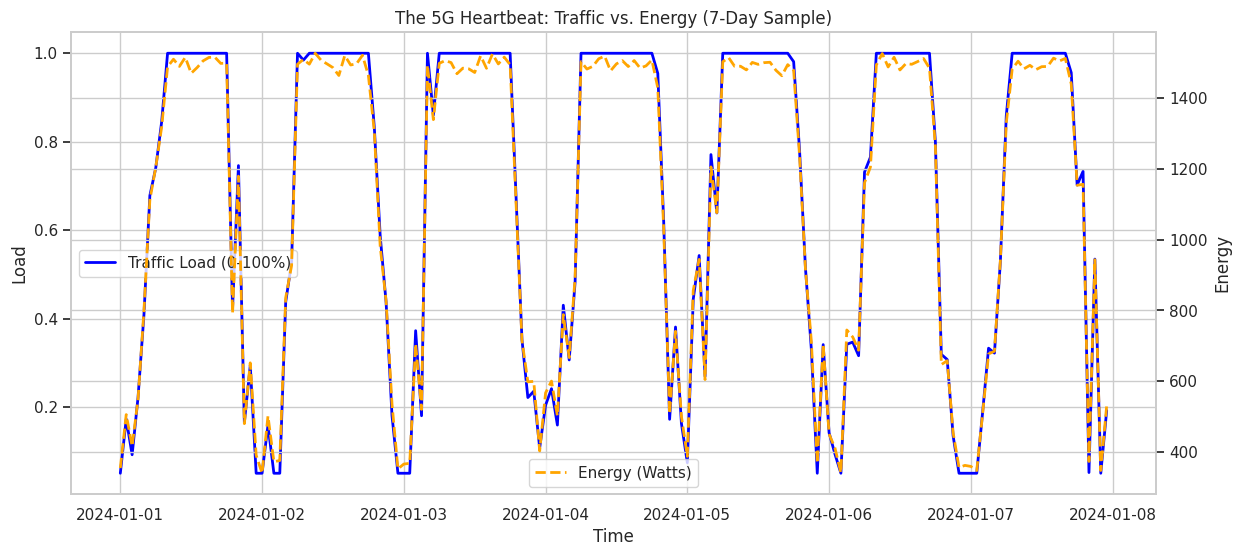

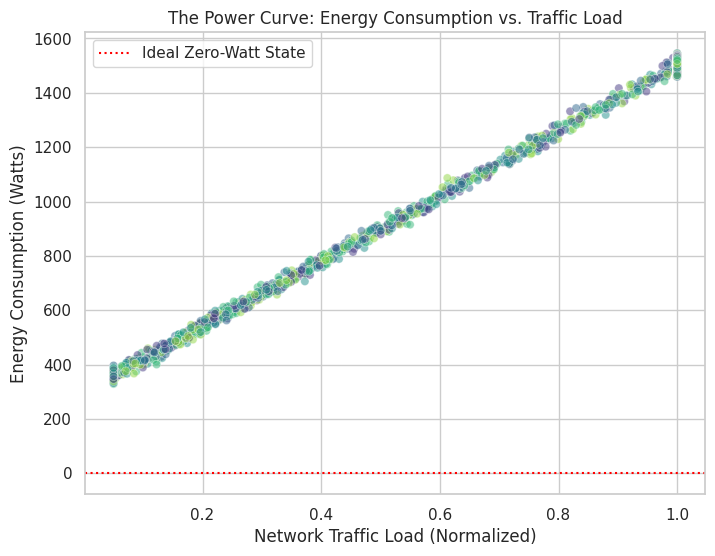

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for professional "Strategy Deck" visuals
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# 1. VISUALIZE THE "HEARTBEAT" (Time Series)
# We'll pick just ONE tower to look at, so the graph isn't messy.
one_tower = df[df['BS'] == 'BS_01'].iloc[:168] # First 7 days (168 hours)

plt.figure()
sns.lineplot(data=one_tower, x='Time', y='Load', label='Traffic Load (0-100%)', color='blue', linewidth=2)
# Create a secondary y-axis for Energy so we can overlay them
ax2 = plt.gca().twinx()
sns.lineplot(data=one_tower, x='Time', y='Energy', label='Energy (Watts)', color='orange', linewidth=2, ax=ax2, linestyle='--')

plt.title("The 5G Heartbeat: Traffic vs. Energy (7-Day Sample)")
plt.show()

# 2. VISUALIZE THE "PHYSICS" (Correlation)
# This proves that Energy increases as Load increases.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.sample(2000), x='Load', y='Energy', hue='BS', alpha=0.5, legend=False, palette='viridis')
plt.title("The Power Curve: Energy Consumption vs. Traffic Load")
plt.xlabel("Network Traffic Load (Normalized)")
plt.ylabel("Energy Consumption (Watts)")

# Add a "Zero-Watt" reference line (Theoretical Ideal)
plt.axhline(y=0, color='red', linestyle=':', label='Ideal Zero-Watt State')
plt.legend()
plt.show()

## Graph 1: See how wide those valleys are? That is a 4-5 hour window every night where we can save massive energy.

## Graph 2: Even when the network is empty, we are paying for 400 Watts per tower. My model attacks this 400-Watt baseline.